## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Gabriel Andrés Tautiva Amado" # @param {"type":"string"}
carnet = 1000113817 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Un centro de cómputo recibe diferentes tareas que deben ser procesadas por sus servidores.
Cada tarea tiene:

Código.

Nombre.

Prioridad.

Las tareas con una prioridad numérica mayor deberán ser procesadas primero.

Ejemplo:

T01 - Compilar proyecto - Prioridad 8 T02 - Generar backup - Prioridad 4 T03 - Renderizar video - Prioridad 10 T04 - Procesar correos - Prioridad 3 T05 - Ejecutar pruebas - Prioridad 7
Para administrar las tareas se deberá utilizar un Max-Heap implementado mediante un arreglo.


## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales:**

**-RQF(01):** Se le solicitara al usuario una cantidad de tareas, se solicitara el nombre, codigo y prioridad de la terea que guarde el usuario.

**-RQF(02):** Cada tarea guardada debe mostrarse en el orden que fue ingresada por el usuario.

**-RQF(03):** Se utilizara "Max-heap" en la lista de tareas ya ingresada con el fin de mostrar el arbol formado a partir de esta.

**-RQF(04):** A partir del "Max-heap" se debe poder buscar la tarea con mayor prioridad, se podra procesar la tarea mas priorizada para retirarla y mostrar cual fue la que se proceso.

**-RQF(05):** Se podra ingresar una nueva tarea y reorganizar el "heap" al realizar algun cambio(procesar, insertar).

**-RQF(06):** La lista de prioridades se ordenara de la menor hasta la mayor con "Heapsort".

**-RQF(07):** Se elmpleara un menu para mejor interaccion.

Lista requerimientos **no funcionales:**

**-RQNF(01):** Se realizara el programa modular para facilitar ajustes o correcciones rapidas.

**-RQNF(02):** Los enunciados deben ser claros y entendibles para cualquier usuario.

**-RQNF(03):** El programa se hara el phyton dado que es el que mejor usamos y es de mayor facilidad para entender.

**-RQNF(04):** Las respuestas no deben tardar se realizaran de manera rapida y eficiente por lo que el codigo no tendra un costo elevado.


## 3) Historias de usuario **[2 pts]**

**-HU(01):** 

Menu interactivo para el usuario:

**-Entrada:** El usuario digito un numero entero positivo y se dirigio a la opcion seleccionada.

**-Error:** El menu dirige a una opcion no seleccionada, o no lleva a ninguna otra parte del programa generando un bucle en el menu.

**-HU(02):** 

Ingreso de las tareas:

**-Entrada:** Se digito adecuadamente el nombre, codigo, prioridad de cada tarea.

**-Salida:** No se guardo en la lista alguna tarea, se asigna un codigo, nombre o prioridad a una tarea no seleccionada.

**-HU(03):**

Insertar, procesar y retirar tareas:

**-Entrada:** Se proceso y mostro la tarea retirada y la procesada, se reorganizo el arbol y se muestra, se inserto una nueva tarea adecuadamente.

**-Error:** No se reorganizo el arbol a l realizar un cambio, una tarea retirada sigue existente o no se muestra la que se proceso, al intertar no se guarda el proceso realizado.


## 4) Diagramas de flujo **[5 pts]**

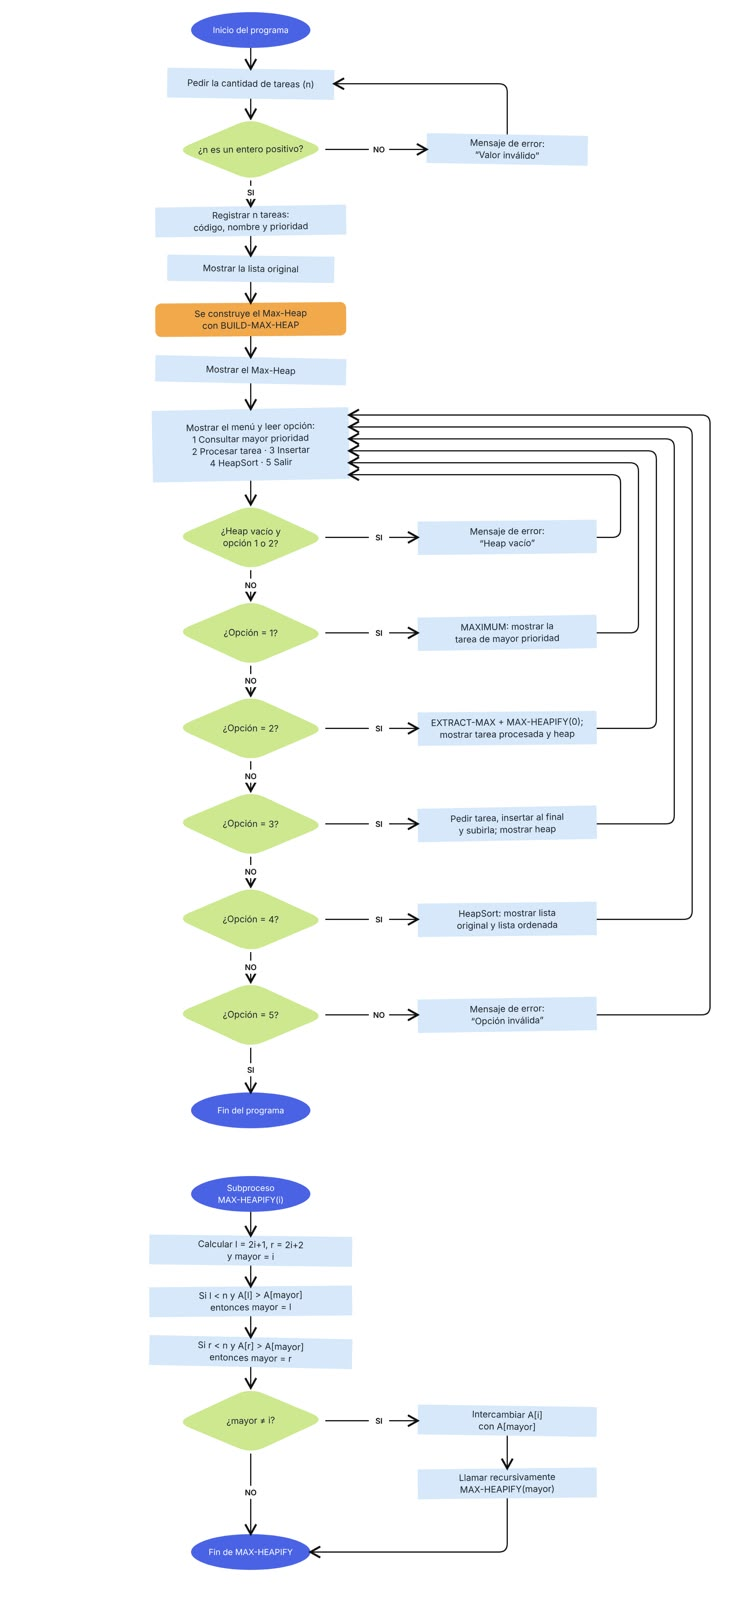

Se puede observar las opciones que brinda el menu, con valores del 1 al 5, cada opcion lleva a un proceso en el que se utiliza max-heap o heapsort, se pueden inertar y procesar tareas que ya han sido guradadas, solo se observa fallos al no ingresar un numero valido en el menu ya que al guardar un nombre, codigo o prioridad se almacena en diversos tipos de valores por lo que no hay ningun incomveniente, en la parte de al fondo se ve el proceso de la cola y orden del arbol.


### 5) Análisis de complejidad **[15 pts]**

En HeapSort, tanto el mejor como el peor caso comparten una complejidad asintotica de $O(n \log n)$ debido a que el algoritmo ejecuta su rutina completa sin importar el orden inicial de los datos.

El algoritmo de HeapSort no detecta si la lista ya está ordenada, por lo que nunca detiene su ejecución antes de tiempo. Durante el ordenamiento, el elemento máximo (la raíz) se extrae $n$ veces. Tras cada extracción, el espacio de la raíz se llena con el último elemento del Heap (una hoja). Al ser un valor de la parte más baja del árbol, suele ser un número pequeño. Ese valor pequeño obliga a la función a evaluar y realizar intercambios para meterlo nuevamente nivel por nivel hasta el final del arbol. Este recorrido por la altura del árbol cuesta estrictamente $O(\log n)$.

$T(n) = O(n \log n)$.

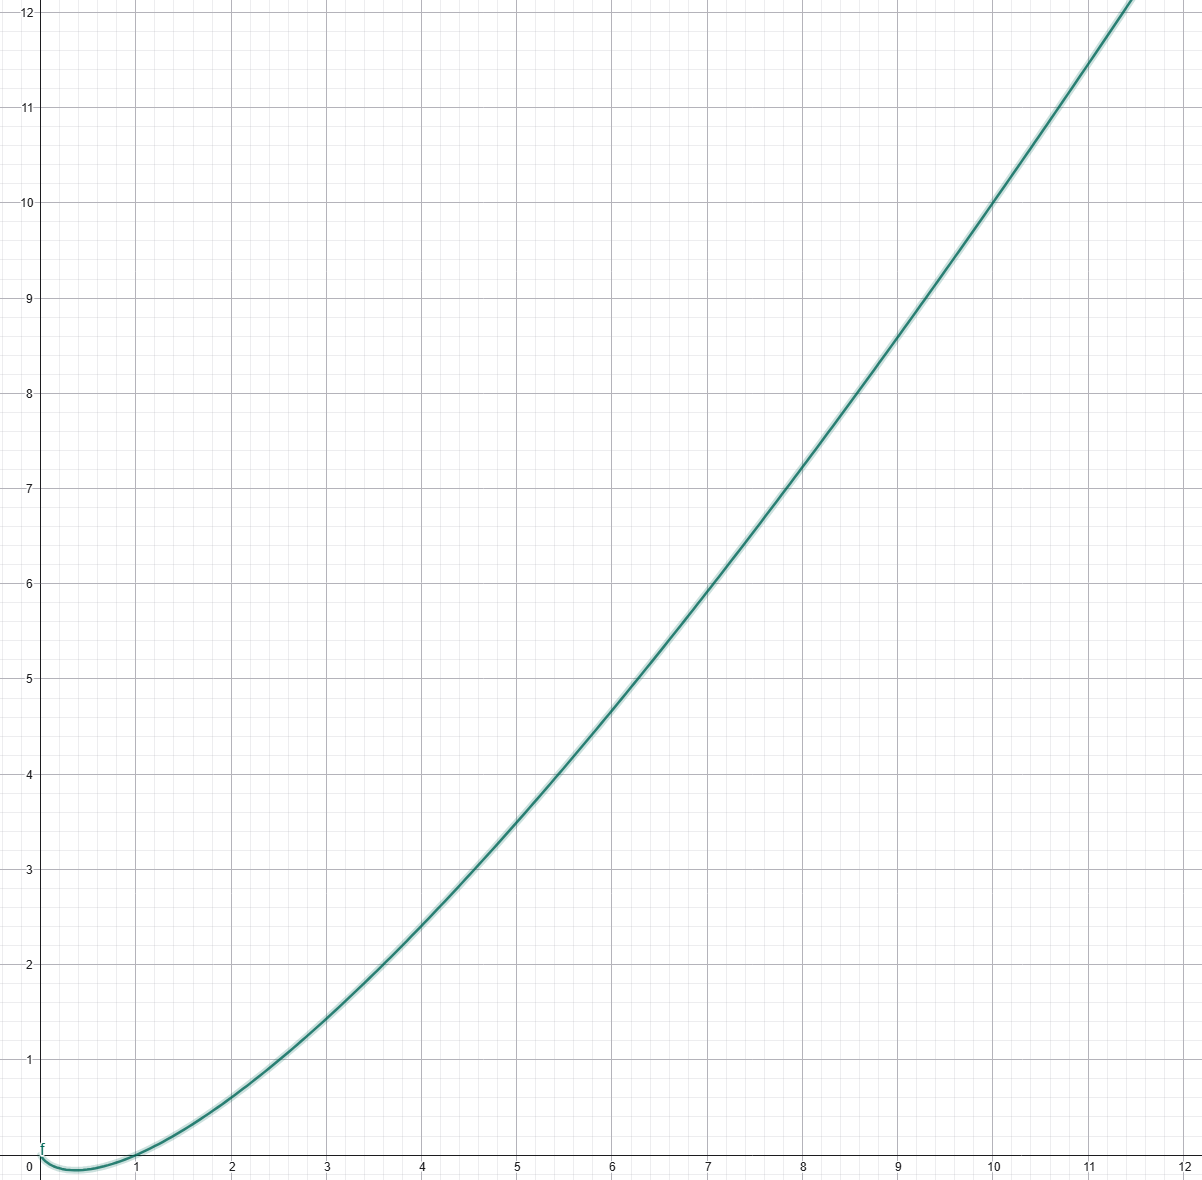

Mejor caso:

$T(n) = O(n)$.

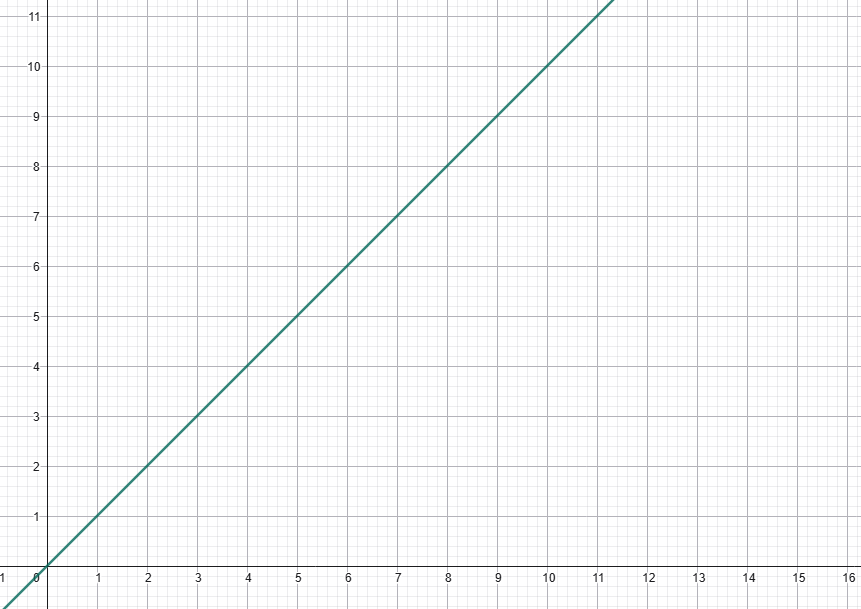

Ocurre cuando todos los datos ingresados son el mismo dato, pues no hay que realizar intercambios

## 6) Código funcional **[15 pts]**


In [ ]:
def max_heapify(arreglo, n, i):
    izq = 2 * i + 1
    der = 2 * i + 2
    mayor = i

    if izq < n and arreglo[izq]['prioridad'] > arreglo[mayor]['prioridad']:
        mayor = izq
    
    if der < n and arreglo[der]['prioridad'] > arreglo[mayor]['prioridad']:
        mayor = der

    if mayor != i:
        arreglo[i], arreglo[mayor] = arreglo[mayor], arreglo[i]
        max_heapify(arreglo, n, mayor)

def build_max_heap(arreglo):
    n = len(arreglo)
    for i in range(n // 2 - 1, -1, -1):
        max_heapify(arreglo, n, i)

def maximum(arreglo):
    if len(arreglo) == 0:
        return None
    return arreglo[0]

def extract_max(arreglo):
    if len(arreglo) == 0:
        return None
    n = len(arreglo)
    tarea_max = arreglo[0]
    arreglo[0] = arreglo[n - 1]
    arreglo.pop()
    
    if len(arreglo) > 0:
        max_heapify(arreglo, len(arreglo), 0)
    
    return tarea_max

def insertar_tarea(arreglo, tarea):
    arreglo.append(tarea)
    i = len(arreglo) - 1
    
    while i > 0:
        padre = (i - 1) // 2
        if arreglo[padre]['prioridad'] < arreglo[i]['prioridad']:
            arreglo[padre], arreglo[i] = arreglo[i], arreglo[padre]
            i = padre
        else:
            break

def heapsort_manual(prioridades):
    def heapify_num(arr, n, i):
        izq = 2 * i + 1
        der = 2 * i + 2
        mayor = i
        if izq < n and arr[izq] > arr[mayor]:
            mayor = izq
        if der < n and arr[der] > arr[mayor]:
            mayor = der
        if mayor != i:
            arr[i], arr[mayor] = arr[mayor], arr[i]
            heapify_num(arr, n, mayor)

    n = len(prioridades)
    
    for i in range(n // 2 - 1, -1, -1):
        heapify_num(prioridades, n, i)

    for i in range(n - 1, 0, -1):
        prioridades[i], prioridades[0] = prioridades[0], prioridades[i]
        heapify_num(prioridades, i, 0)
        
    return prioridades

def imprimir_arbol_sencillo(arreglo):
    n = len(arreglo)
    if n == 0: 
        return
    
    print(f"\n      {arreglo[0]['prioridad']}")
    if n > 1:
        print("     /  \\")
        izq_val = arreglo[1]['prioridad'] if 1 < n else " "
        der_val = arreglo[2]['prioridad'] if 2 < n else " "
        print(f"    {izq_val}    {der_val}")
    if n > 3:
        print("   / \\  / \\")
        i_i = arreglo[3]['prioridad'] if 3 < n else " "
        i_d = arreglo[4]['prioridad'] if 4 < n else " "
        d_i = arreglo[5]['prioridad'] if 5 < n else " "
        d_d = arreglo[6]['prioridad'] if 6 < n else " "
        print(f"  {i_i}  {i_d} {d_i}  {d_d}\n")

def pedir_entero_positivo(mensaje):
    while True:
        try:
            valor = int(input(mensaje))
            if valor > 0:
                return valor
            print("Valor invalido. Ingrese un entero positivo.")
        except ValueError:
            print("Valor invalido. Ingrese un numero.")

def main():
    print("--- REGISTRO INICIAL DE TAREAS ---")
    n = pedir_entero_positivo("Ingrese la cantidad de tareas a registrar: ")
    print(f">> Cantidad de tareas a registrar: {n}")
    
    tareas = []
    prioridades_originales = []
    
    for i in range(n):
        print(f"\nTarea {i+1}:")
        codigo = input("Codigo: ")
        nombre = input("Nombre: ")
        prioridad = pedir_entero_positivo("Prioridad: ")
        
        print(f"-> Registrado: {codigo} - {nombre} | Prioridad: {prioridad}")
        
        tarea = {'codigo': codigo, 'nombre': nombre, 'prioridad': prioridad}
        tareas.append(tarea)
        prioridades_originales.append(prioridad)
        
    print(f"\nLista original de prioridades: {prioridades_originales}")
    
    build_max_heap(tareas)
    
    print(f"Max-Heap de prioridades: {[t['prioridad'] for t in tareas]}")
    imprimir_arbol_sencillo(tareas)
    
    while True:
        print("\n\tMENU DE GESTION DE TAREAS")
        print("1. Consultar la tarea de mayor prioridad (MAXIMUM)")
        print("2. Procesar la tarea de mayor prioridad (EXTRACT-MAX)")
        print("3. Insertar una nueva tarea")
        print("4. Ejecutar HeapSort")
        print("5. Salir")
        
        opcion = input("Seleccione una opcion: ")
        print(f">> Opcion seleccionada: {opcion}") 
        
        if len(tareas) == 0 and opcion in ['1', '2']:
            print("Heap vacio.")
            continue
            
        if opcion == '1':
            max_t = maximum(tareas)
            print(f"\nTarea de mayor prioridad: {max_t['codigo']} - {max_t['nombre']} | Prioridad: {max_t['prioridad']}")
            
        elif opcion == '2':
            t_procesada = extract_max(tareas)
            print(f"\nTarea procesada: {t_procesada['codigo']} - {t_procesada['nombre']}")
            print(f"Nuevo Heap (prioridades): {[t['prioridad'] for t in tareas]}")
            imprimir_arbol_sencillo(tareas)
            
        elif opcion == '3':
            print("\n--- Insertar Nueva Tarea ---")
            codigo = input("Codigo: ")
            nombre = input("Nombre: ")
            prioridad = pedir_entero_positivo("Prioridad: ")
            
            print(f"-> Tarea insertada: {codigo} - {nombre} | Prioridad: {prioridad}")
            
            nueva_t = {'codigo': codigo, 'nombre': nombre, 'prioridad': prioridad}
            
            insertar_tarea(tareas, nueva_t)
            print(f"Nuevo Heap (prioridades): {[t['prioridad'] for t in tareas]}")
            imprimir_arbol_sencillo(tareas)
            
        elif opcion == '4':
            lista_para_ordenar = [t['prioridad'] for t in tareas]
            print(f"\nLista original (Estado actual): {lista_para_ordenar}")
            print(f"Max-Heap: {lista_para_ordenar}") 
            
            lista_ordenada = heapsort_manual(lista_para_ordenar)
            print(f"Lista ordenada (HeapSort): {lista_ordenada}")
            
        elif opcion == '5':
            print("Saliendo del programa...")
            break
            
        else:
            print("Opcion invalida. Intente de nuevo.")

main()

## 7) Tests aplicados **[15 pts]**

In [1]:
def max_heapify(arreglo, n, i):
    izq = 2 * i + 1
    der = 2 * i + 2
    mayor = i

    if izq < n and arreglo[izq]['prioridad'] > arreglo[mayor]['prioridad']:
        mayor = izq
    
    if der < n and arreglo[der]['prioridad'] > arreglo[mayor]['prioridad']:
        mayor = der

    if mayor != i:
        arreglo[i], arreglo[mayor] = arreglo[mayor], arreglo[i]
        max_heapify(arreglo, n, mayor)

def build_max_heap(arreglo):
    n = len(arreglo)
    for i in range(n // 2 - 1, -1, -1):
        max_heapify(arreglo, n, i)

def maximum(arreglo):
    if len(arreglo) == 0:
        return None
    return arreglo[0]

def extract_max(arreglo):
    if len(arreglo) == 0:
        return None
    n = len(arreglo)
    tarea_max = arreglo[0]
    arreglo[0] = arreglo[n - 1]
    arreglo.pop()
    
    if len(arreglo) > 0:
        max_heapify(arreglo, len(arreglo), 0)
    
    return tarea_max

def insertar_tarea(arreglo, tarea):
    arreglo.append(tarea)
    i = len(arreglo) - 1
    
    while i > 0:
        padre = (i - 1) // 2
        if arreglo[padre]['prioridad'] < arreglo[i]['prioridad']:
            arreglo[padre], arreglo[i] = arreglo[i], arreglo[padre]
            i = padre
        else:
            break

def heapsort_manual(prioridades):
    def heapify_num(arr, n, i):
        izq = 2 * i + 1
        der = 2 * i + 2
        mayor = i
        if izq < n and arr[izq] > arr[mayor]:
            mayor = izq
        if der < n and arr[der] > arr[mayor]:
            mayor = der
        if mayor != i:
            arr[i], arr[mayor] = arr[mayor], arr[i]
            heapify_num(arr, n, mayor)

    n = len(prioridades)
    
    for i in range(n // 2 - 1, -1, -1):
        heapify_num(prioridades, n, i)

    for i in range(n - 1, 0, -1):
        prioridades[i], prioridades[0] = prioridades[0], prioridades[i]
        heapify_num(prioridades, i, 0)
        
    return prioridades

def imprimir_arbol_sencillo(arreglo):
    n = len(arreglo)
    if n == 0: 
        return
    
    print(f"\n      {arreglo[0]['prioridad']}")
    if n > 1:
        print("     /  \\")
        izq_val = arreglo[1]['prioridad'] if 1 < n else " "
        der_val = arreglo[2]['prioridad'] if 2 < n else " "
        print(f"    {izq_val}    {der_val}")
    if n > 3:
        print("   / \\  / \\")
        i_i = arreglo[3]['prioridad'] if 3 < n else " "
        i_d = arreglo[4]['prioridad'] if 4 < n else " "
        d_i = arreglo[5]['prioridad'] if 5 < n else " "
        d_d = arreglo[6]['prioridad'] if 6 < n else " "
        print(f"  {i_i}  {i_d} {d_i}  {d_d}\n")

def pedir_entero_positivo(mensaje):
    while True:
        try:
            valor = int(input(mensaje))
            if valor > 0:
                return valor
            print("Valor invalido. Ingrese un entero positivo.")
        except ValueError:
            print("Valor invalido. Ingrese un numero.")

def ejecutar_tests():
    tar_test = [
        {'codigo': 'T01', 'nombre': 'Compilar', 'prioridad': 8},
        {'codigo': 'T02', 'nombre': 'Backup', 'prioridad': 4},
        {'codigo': 'T03', 'nombre': 'Renderizar', 'prioridad': 10},
        {'codigo': 'T04', 'nombre': 'Correos', 'prioridad': 3},
        {'codigo': 'T05', 'nombre': 'Pruebas', 'prioridad': 7},
        {'codigo': 'T07', 'nombre': 'Documentar', 'prioridad': 5}
    ]

    print("PRUEBAS")

    build_max_heap(tar_test)
    prio_bld = [tar['prioridad'] for tar in tar_test]
    esp_bld = [10, 7, 8, 3, 4, 5]
    print(f"\nTest Build-Max-Heap: Se esperaba {esp_bld}, se obtuvo {prio_bld}")
    assert prio_bld == esp_bld
    print("Arbol del Max-Heap:")
    imprimir_arbol_sencillo(tar_test)

    max_tar = maximum(tar_test)
    esp_max = 10
    obt_max = max_tar['prioridad']
    print(f"\nTest Maximum: Se esperaba {esp_max}, se obtuvo {obt_max}")
    assert obt_max == esp_max

    ext_tar = extract_max(tar_test)
    prio_ext = [tar['prioridad'] for tar in tar_test]
    esp_ext_val = 10
    esp_ext_arr = [8, 7, 5, 3, 4]
    obt_ext_val = ext_tar['prioridad']
    print(f"\nTest Extract-Max (Valor extraido): Se esperaba {esp_ext_val}, se obtuvo {obt_ext_val}")
    print(f"Test Extract-Max (Nuevo arreglo): Se esperaba {esp_ext_arr}, se obtuvo {prio_ext}")
    assert obt_ext_val == esp_ext_val
    assert prio_ext == esp_ext_arr
    print("Arbol visual tras extraer el maximo:")
    imprimir_arbol_sencillo(tar_test)

    nueva_tar = {'codigo': 'T06', 'nombre': 'Actualizar', 'prioridad': 12}
    insertar_tarea(tar_test, nueva_tar)
    prio_ins = [tar['prioridad'] for tar in tar_test]
    esp_ins = [12, 7, 8, 3, 4, 5]
    print(f"\nTest Insertar Tarea: Se esperaba {esp_ins}, se obtuvo {prio_ins}")
    assert prio_ins == esp_ins
    print("Arbol tras insertar la nueva tarea:")
    imprimir_arbol_sencillo(tar_test)

    lis_ord = heapsort_manual(prio_ins)
    esp_ord = [3, 4, 5, 7, 8, 12]
    print(f"\nTest HeapSort: Se esperaba {esp_ord}, se obtuvo {lis_ord}")
    assert lis_ord == esp_ord

    print("\nTodos los tests se ejecutaron y validaron correctamente.")

ejecutar_tests()


PRUEBAS

Test Build-Max-Heap: Se esperaba [10, 7, 8, 3, 4, 5], se obtuvo [10, 7, 8, 3, 4, 5]
Arbol del Max-Heap:

      10
     /  \
    7    8
   / \  / \
  3  4 5   


Test Maximum: Se esperaba 10, se obtuvo 10

Test Extract-Max (Valor extraido): Se esperaba 10, se obtuvo 10
Test Extract-Max (Nuevo arreglo): Se esperaba [8, 7, 5, 3, 4], se obtuvo [8, 7, 5, 3, 4]
Arbol visual tras extraer el maximo:

      8
     /  \
    7    5
   / \  / \
  3  4     


Test Insertar Tarea: Se esperaba [12, 7, 8, 3, 4, 5], se obtuvo [12, 7, 8, 3, 4, 5]
Arbol tras insertar la nueva tarea:

      12
     /  \
    7    8
   / \  / \
  3  4 5   


Test HeapSort: Se esperaba [3, 4, 5, 7, 8, 12], se obtuvo [3, 4, 5, 7, 8, 12]

Todos los tests se ejecutaron y validaron correctamente.
